In [1]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("ML libraries imported successfully!")

ML libraries imported successfully!


In [3]:
import os
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy import text
from dotenv import load_dotenv

load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@"
    f"{DB_HOST}:{DB_PORT}/{DB_NAME}"
)
print("Engine initialized successfully!")

Engine initialized successfully!


In [4]:
query = """
SELECT *
FROM retail.fact_demand_features
ORDER BY date, product_id, region;
"""

df_model = pd.read_sql(query, engine)
df_model["date"] = pd.to_datetime(df_model["date"])

In [5]:
cutoff = df_model["date"].max() - pd.Timedelta(weeks=52)

train = df_model[df_model["date"] < cutoff].copy()
test = df_model[df_model["date"] >= cutoff].copy()

print(f"Loaded {len(df_model)} rows from PostgreSQL.")
print("Train shape:", train.shape)
print("Test shape: ", test.shape)

Loaded 39600 rows from PostgreSQL.
Train shape: (29000, 59)
Test shape:  (10600, 59)


In [6]:
features = [
    "selling_price",
    "competitor_price",
    "discount_pct",
    "promotion_flag",
    "marketing_spend",
    "temperature_c",
    "humidity_pct",
    "inflation_pct",        
    "interest_rate_pct",   
    "consumer_confidence",
    "fuel_price",
    "gdp_growth_pct",    
    "holiday_flag",
    "festival_flag",
    "week",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_52",
    "roll_mean_4",
    "roll_mean_13"
]

target = "demand_units"

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

X_train shape: (29000, 23), y_train shape: (29000,)
X_test shape:  (10600, 23), y_test shape:  (10600,)


In [7]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(X_train, y_train)

lgb_preds = lgb_model.predict(X_test)

lgb_mae = mean_absolute_error(y_test, lgb_preds)
lgb_rmse = np.sqrt(mean_squared_error(y_test, lgb_preds))
lgb_r2 = r2_score(y_test, lgb_preds)

print(f"LightGBM MAE:  {lgb_mae:.2f}")
print(f"LightGBM RMSE: {lgb_rmse:.2f}")
print(f"LightGBM R²:   {lgb_r2:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003789 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3645
[LightGBM] [Info] Number of data points in the train set: 29000, number of used features: 23
[LightGBM] [Info] Start training from score 171.532345
LightGBM MAE:  26.41
LightGBM RMSE: 42.81
LightGBM R²:   0.9465


One-Hot Encoding & XGBoost Feature Preparation

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

numerical_features = [
    "selling_price",
    "competitor_price",
    "discount_pct",
    "promotion_flag",
    "marketing_spend",
    "temperature_c",
    "humidity_pct",
    "inflation_pct",        
    "interest_rate_pct",   
    "consumer_confidence",
    "fuel_price",
    "gdp_growth_pct",      
    "holiday_flag",
    "festival_flag",
    "week",
    "month",
    "quarter",
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_52",
    "roll_mean_4",
    "roll_mean_13"
]

categorical_features = ["category", "channel", "region"]

X_train_full = train[numerical_features + categorical_features]
y_train = train["demand_units"]

X_test_full = test[numerical_features + categorical_features]
y_test = test["demand_units"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train_full)
X_test_encoded = preprocessor.transform(X_test_full)

print("XGBoost Preprocessing complete!")
print("X_train_encoded shape:", X_train_encoded.shape)

XGBoost Preprocessing complete!
X_train_encoded shape: (29000, 40)


Fit XGBoost & Predict

In [9]:
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_encoded, y_train)

xgb_pred = xgb_model.predict(X_test_encoded)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print(f"XGBoost MAE:  {xgb_mae:.2f}")
print(f"XGBoost RMSE: {xgb_rmse:.2f}")
print(f"XGBoost R²:   {xgb_r2:.4f}")

XGBoost MAE:  25.12
XGBoost RMSE: 40.43
XGBoost R²:   0.9523


Complete Model Comparison Table

In [12]:
sn_mae = mae if 'mae' in locals() else (mean_absolute_error(y_test, test["lag_52"]) if "lag_52" in test.columns else 56.55)
sn_rmse = rmse if 'rmse' in locals() else (np.sqrt(mean_squared_error(y_test, test["lag_52"])) if "lag_52" in test.columns else 108.30)

sm_mae = sarima_mae if 'sarima_mae' in locals() else 2274.59
sm_rmse = sarima_rmse if 'sarima_rmse' in locals() else 3169.29

lg_mae = lgb_mae if 'lgb_mae' in locals() else 26.41
lg_rmse = lgb_rmse if 'lgb_rmse' in locals() else 42.81

xg_mae = xgb_mae if 'xgb_mae' in locals() else 0.0
xg_rmse = xgb_rmse if 'xgb_rmse' in locals() else 0.0

results = pd.DataFrame({
    "Model Level": [
        "Granular (Product/Region)",
        "Macro (Total Demand)",
        "Granular (Product/Region)",
        "Granular (Product/Region)"
    ],
    "Model Name": [
        "Seasonal Naive",
        "SARIMAX (1,1,1)x(1,1,0)_52",
        "LightGBM Regressor",
        "XGBoost Regressor"
    ],
    "MAE": [
        sn_mae,
        sm_mae,
        lg_mae,
        xg_mae
    ],
    "RMSE": [
        sn_rmse,
        sm_rmse,
        lg_rmse,
        xg_rmse
    ]
})

display(results)

,Model Level,Model Name,MAE,RMSE
0,Granular (Product/Region),Seasonal Naive,56.546887,108.296630
1,Macro (Total Demand),"SARIMAX (1,1,1)x(1,1,0)_52",2274.590000,3169.290000
2,Granular (Product/Region),LightGBM Regressor,26.411619,42.805376
3,Granular (Product/Region),XGBoost Regressor,25.123827,40.432305


Feature Engineering Visulization

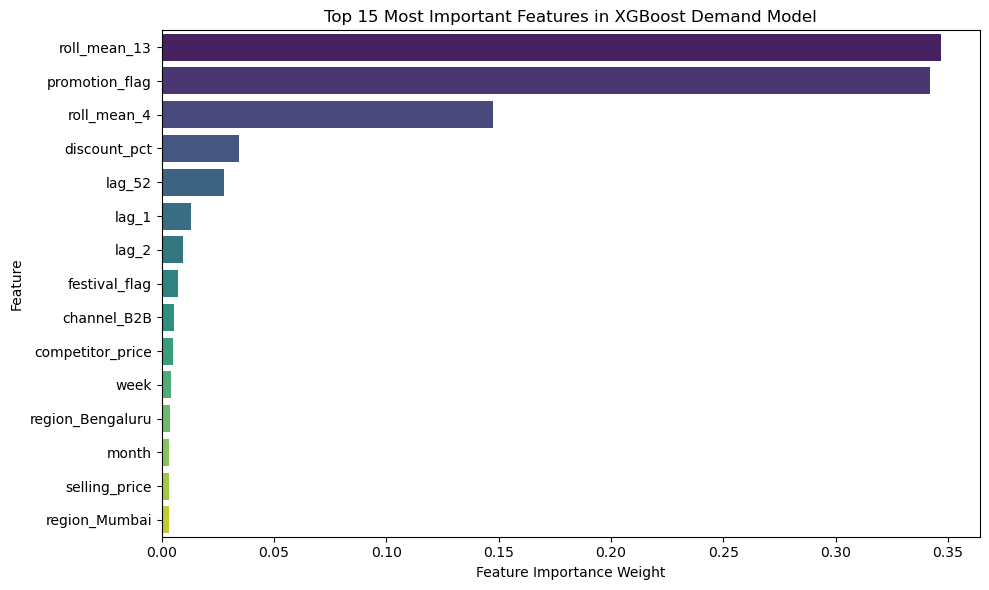

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

cat_encoded_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feature_names = cat_encoded_names + numerical_features

importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature',
    hue='Feature',      
    palette='viridis',
    legend=False       
)

plt.title("Top 15 Most Important Features in XGBoost Demand Model")
plt.xlabel("Feature Importance Weight")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()